<a href="https://colab.research.google.com/github/rahulsaha1234/Devlearn_Educhain/blob/main/student_attendance.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

STUDENT ATTENDANCE DATA


,Student,Attendance,Study_Hours,Assignments,Result
0,Rahul,85,4,8,Pass
1,Raj,90,5,9,Fail
2,Pratik,78,3,7,Pass
3,Shilpa,92,6,10,Pass
4,Shubham,88,5,9,Pass
5,Wriddiman,75,2,6,Pass
6,Debraj,66,3,7,Fail
7,Shaw,90,6,10,Pass
8,Banerjee,82,4,8,Pass
9,Saha,56,1,3,Pass



features/variables and the target variable

FEATURES:
1. Attendance
2. Study_Hours
3. Assignments

TARGET VARIABLE:
Result

 Calculate mean, median, and mode for one suitable numerical feature

STATISTICAL ANALYSIS
Mean Attendance   : 79.5
Median Attendance : 82.5
Mode Attendance   : [82, 85, 90]

Identify at least one possible outlier using a suitable method

OUTLIER DETECTION USING IQR
Q1            : 76.5
Q3            : 88.5
IQR           : 12.0
Lower Bound   : 58.5
Upper Bound   : 106.5

POSSIBLE OUTLIERS


,Student,Attendance
9,Saha,56
13,Kumari,40



SUMMARY TABLE


,Measure,Value
0,Mean,79.5
1,Median,82.5
2,Mode,"[82, 85, 90]"
3,Q1,76.5
4,Q3,88.5
5,IQR,12.0
6,Lower Bound,58.5
7,Upper Bound,106.5



PRESENT THE FINDINGS USING ONE SUITABLE TABLE OR CHART


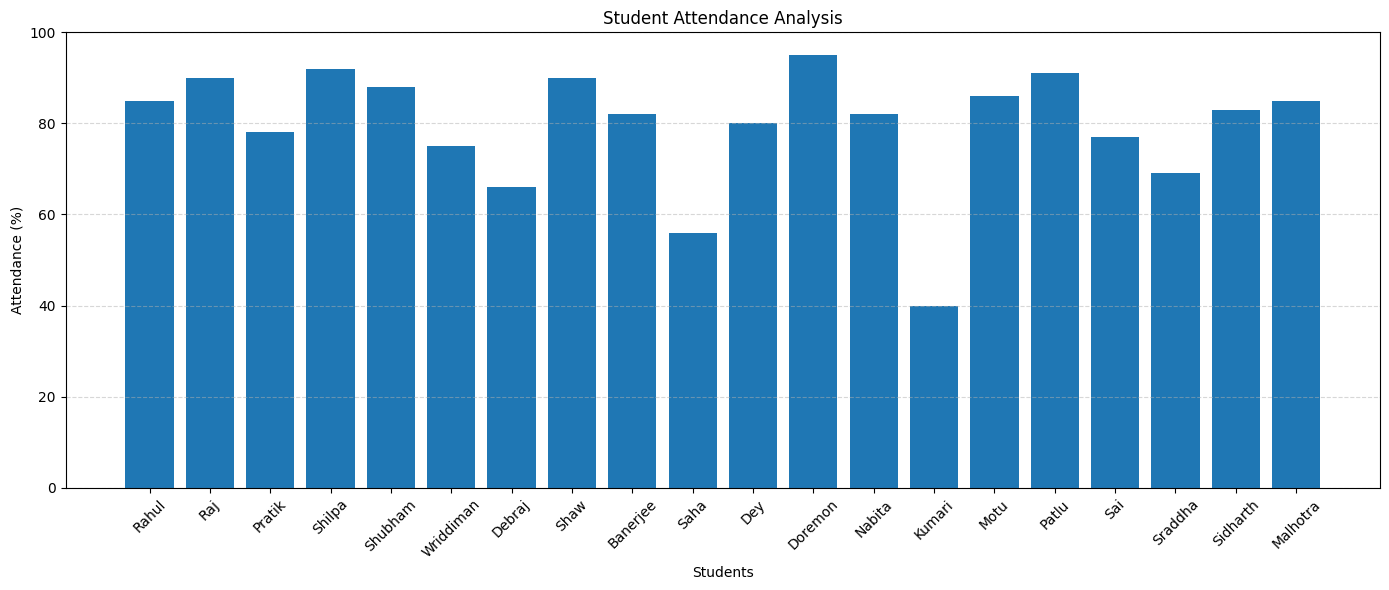


CONCLUSION
The mean attendance is 79.50%.
The median attendance is 82.50%.
There is no single mode attendance.

The IQR method identified the following possible outlier(s):
Saha - 56% attendance
Kumari - 40% attendance

Overall, most students have satisfactory attendance.
Students with unusually low attendance may require attention.


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt


#  Dataset


data = {
    "Student": [
        "Rahul", "Raj", "Pratik", "Shilpa", "Shubham",
        "Wriddiman", "Debraj", "Shaw", "Banerjee", "Saha",
        "Dey", "Doremon", "Nabita", "Kumari", "Motu",
        "Patlu", "Sai", "Sraddha", "Sidharth", "Malhotra"
    ],

    "Attendance": [
        85, 90, 78, 92, 88,
        75, 66, 90, 82, 56,
        80, 95, 82, 40, 86,
        91, 77, 69, 83, 85
    ],

    "Study_Hours": [
        4, 5, 3, 6, 5,
        2, 3, 6, 4, 1,
        4, 5, 3, 1, 4,
        5, 3, 2, 4, 5
    ],

    "Assignments": [
        8, 9, 7, 10, 9,
        6, 7, 10, 8, 3,
        8, 9, 7, 3, 8,
        9, 7, 6, 8, 9
    ],

    "Result": [
        "Pass", "Fail", "Pass", "Pass", "Pass",
        "Pass", "Fail", "Pass", "Pass", "Pass",
        "Fail", "Pass", "Pass", "Fail", "Pass",
        "Pass", "Pass", "Pass", "Pass", "Pass"
    ]
}

# DataFrame
df = pd.DataFrame(data)

print("STUDENT ATTENDANCE DATA")
print("=======================")

display(df)



# 2. features/variables and the target variable
print("\nfeatures/variables and the target variable")
print("==================")

print("\nFEATURES:")
print("1. Attendance")
print("2. Study_Hours")
print("3. Assignments")

print("\nTARGET VARIABLE:")
print("Result")



# 3.	Calculate mean, median, and mode for one suitable numerical feature.
print("\n Calculate mean, median, and mode for one suitable numerical feature")
print("==================")

attendance = df["Attendance"]

mean_attendance = attendance.mean()
median_attendance = attendance.median()
mode_attendance = attendance.mode()

print("\nSTATISTICAL ANALYSIS")
print("====================")

print("Mean Attendance   :", mean_attendance)
print("Median Attendance :", median_attendance)

if len(mode_attendance) == 0:
    print("Mode Attendance   : No mode")
else:
    print("Mode Attendance   :", mode_attendance.tolist())



# 4.Identify at least one possible outlier using a suitable method.
print("\nIdentify at least one possible outlier using a suitable method")
print("==================")


Q1 = attendance.quantile(0.25)
Q3 = attendance.quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("\nOUTLIER DETECTION USING IQR")
print("===========================")

print("Q1            :", Q1)
print("Q3            :", Q3)
print("IQR           :", IQR)
print("Lower Bound   :", lower_bound)
print("Upper Bound   :", upper_bound)


# Find outliers
outliers = df[
    (df["Attendance"] < lower_bound) |
    (df["Attendance"] > upper_bound)
]

print("\nPOSSIBLE OUTLIERS")
print("=================")

if len(outliers) == 0:
    print("No outliers found.")
else:
    display(outliers[["Student", "Attendance"]])



# 5. Summary Table

summary = pd.DataFrame({
    "Measure": [
        "Mean",
        "Median",
        "Mode",
        "Q1",
        "Q3",
        "IQR",
        "Lower Bound",
        "Upper Bound"
    ],

    "Value": [
        mean_attendance,
        median_attendance,
        str(mode_attendance.tolist()),
        Q1,
        Q3,
        IQR,
        lower_bound,
        upper_bound
    ]
})

print("\nSUMMARY TABLE")
print("=============")

display(summary)



# 5.	Present the findings using one suitable table or chart
print("\nPRESENT THE FINDINGS USING ONE SUITABLE TABLE OR CHART")
print("==================")

plt.figure(figsize=(14, 6))

plt.bar(df["Student"], df["Attendance"])

plt.xlabel("Students")
plt.ylabel("Attendance (%)")
plt.title("Student Attendance Analysis")

plt.xticks(rotation=45)

plt.ylim(0, 100)

plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()

plt.show()



print("\nCONCLUSION")
print("===========")

print(f"The mean attendance is {mean_attendance:.2f}%.")
print(f"The median attendance is {median_attendance:.2f}%.")

if len(mode_attendance) == 1:
    print(f"The mode attendance is {mode_attendance.iloc[0]}%.")
else:
    print("There is no single mode attendance.")

if len(outliers) > 0:
    print("\nThe IQR method identified the following possible outlier(s):")

    for index, row in outliers.iterrows():
        print(f"{row['Student']} - {row['Attendance']}% attendance")

print("\nOverall, most students have satisfactory attendance.")
print("Students with unusually low attendance may require attention.")